# Signal Peptide Detection — Sliding Window vs RNN vs LSTM (PyTorch)

This notebook follows the style of **Chapter 9/10** and adds an end-to-end bioinformatics example:

1. Obtain a labeled protein dataset from **UniProt** (reviewed Swiss-Prot records with signal-peptide annotations).
2. Train a **sliding-window baseline** for residue-level signal peptide detection.
3. Train recurrent models (**SimpleRNN** and **LSTM**) for the same residue-labeling task.

The task is residue-wise binary labeling on the N-terminus: signal peptide residue (1) vs not (0).

In [1]:
# If needed:
# pip install numpy matplotlib scikit-learn torch

from pathlib import Path
import re
import urllib.parse
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, matthews_corrcoef,
    roc_auc_score, average_precision_score, precision_recall_curve
)

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 1) Download and parse a UniProt signal-peptide dataset

We query UniProtKB (reviewed proteins), retrieve sequence + signal peptide annotation, and convert annotations to residue-level labels.

In [2]:
DATA_DIR = Path("data/signal_peptides")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CACHE_TSV = DATA_DIR / "uniprot_signal.tsv"

UNIPROT_QUERY = "reviewed:true AND length:[40 TO 800]"
FIELDS = "accession,sequence,ft_signal"
MAX_RECORDS = 4000

def fetch_uniprot_tsv(query, fields, max_records=2000):
    base = "https://rest.uniprot.org/uniprotkb/search"
    params = {
        "query": query,
        "fields": fields,
        "format": "tsv",
        "size": 500,
    }

    next_url = base + "?" + urllib.parse.urlencode(params)
    chunks = []
    n_rows = 0

    while next_url and n_rows < max_records:
        req = urllib.request.Request(next_url, headers={"User-Agent": "EkmanTeaching/1.0"})
        with urllib.request.urlopen(req, timeout=60) as resp:
            text = resp.read().decode("utf-8", errors="ignore")
            lines = text.strip().splitlines()
            if not lines:
                break

            if not chunks:
                chunks.extend(lines)
                n_rows += max(0, len(lines) - 1)
            else:
                chunks.extend(lines[1:])
                n_rows += len(lines) - 1

            link = resp.headers.get("Link", "")
            m = re.search(r"<([^>]+)>;\s*rel=\"next\"", link)
            next_url = m.group(1) if m else None

    return "\n".join(chunks) + "\n"


def parse_signal_ranges(signal_field):
    if signal_field is None:
        return []
    txt = str(signal_field).strip()
    if txt == "" or txt.lower() == "nan":
        return []

    ranges = []
    for a, b in re.findall(r"(\d+)\.\.(\d+)", txt):
        s = int(a) - 1
        e = int(b)
        if e > s:
            ranges.append((s, e))
    return ranges


def load_dataset_from_tsv(tsv_text):
    lines = [ln for ln in tsv_text.splitlines() if ln.strip()]
    header = lines[0].split("\t")
    col = {name: idx for idx, name in enumerate(header)}

    accessions = []
    sequences = []
    labels = []

    aa_allowed = set("ACDEFGHIKLMNPQRSTVWYXBZUOJ")

    for ln in lines[1:]:
        parts = ln.split("\t")
        if len(parts) < len(header):
            continue

        acc = parts[col.get("Entry", 0)]
        seq = parts[col.get("Sequence", 1)].strip().upper()
        sig = parts[col.get("Signal peptide", 2)] if "Signal peptide" in col else ""

        if len(seq) < 30 or len(seq) > 1000:
            continue
        if not set(seq).issubset(aa_allowed):
            continue

        y = np.zeros(len(seq), dtype=np.int64)
        for s, e in parse_signal_ranges(sig):
            s = max(0, s)
            e = min(len(seq), e)
            if e > s:
                y[s:e] = 1

        accessions.append(acc)
        sequences.append(seq)
        labels.append(y)

    return accessions, sequences, labels


if CACHE_TSV.exists():
    print("Using cached file:", CACHE_TSV)
    tsv_text = CACHE_TSV.read_text(encoding="utf-8", errors="ignore")
else:
    print("Downloading UniProt TSV...")
    tsv_text = fetch_uniprot_tsv(UNIPROT_QUERY, FIELDS, max_records=MAX_RECORDS)
    CACHE_TSV.write_text(tsv_text, encoding="utf-8")
    print("Saved:", CACHE_TSV)

accessions, sequences, labels = load_dataset_from_tsv(tsv_text)

num_pos_proteins = int(sum(int(y.sum() > 0) for y in labels))
num_neg_proteins = len(labels) - num_pos_proteins
num_pos_residues = int(sum(int(y.sum()) for y in labels))
num_total_residues = int(sum(len(y) for y in labels))

print(f"Proteins: {len(labels)} | with signal peptide: {num_pos_proteins} | without: {num_neg_proteins}")
print(f"Residues: total={num_total_residues:,} | signal={num_pos_residues:,} ({100*num_pos_residues/max(1,num_total_residues):.2f}%)")

Saved: data/signal_peptides/uniprot_signal.tsv
Proteins: 3996 | with signal peptide: 726 | without: 3270
Residues: total=1,579,173 | signal=17,355 (1.10%)


In [ ]:
# Quick EDA
lengths = np.array([len(s) for s in sequences], dtype=np.int64)
sig_lengths = np.array([int(y.sum()) for y in labels], dtype=np.int64)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(lengths, bins=40)
plt.xlabel("protein length")
plt.ylabel("count")
plt.title("Sequence length distribution")

plt.subplot(1, 2, 2)
plt.hist(sig_lengths[sig_lengths > 0], bins=30)
plt.xlabel("signal peptide length")
plt.ylabel("count")
plt.title("Annotated signal peptide lengths")

plt.tight_layout()
plt.show()

## 2) Train/test split and residue window extraction

To focus on signal peptides, we train on the **N-terminus** only (first `NTERM_LEN` residues).

In [3]:
NTERM_LEN = 70
TRAIN_FRAC = 0.8

idx = np.arange(len(sequences))
rng = np.random.default_rng(0)
rng.shuffle(idx)
split = int(TRAIN_FRAC * len(idx))
idx_train = idx[:split]
idx_test = idx[split:]

seq_train = [sequences[i] for i in idx_train]
lab_train = [labels[i] for i in idx_train]
seq_test = [sequences[i] for i in idx_test]
lab_test = [labels[i] for i in idx_test]

print(f"Train proteins: {len(seq_train)} | Test proteins: {len(seq_test)}")

Train proteins: 3196 | Test proteins: 800


## 3) Baseline model: sliding window (logistic classifier)

Each residue is represented by a local amino-acid window around that position.

In [4]:
AA = "ACDEFGHIKLMNPQRSTVWY"
aa_to_idx = {a: i for i, a in enumerate(AA)}
UNK_IDX = len(AA)
VOCAB_SIZE = len(AA) + 1

WINDOW = 15
R = WINDOW // 2

def aa_index(ch):
    return aa_to_idx.get(ch, UNK_IDX)

def make_residue_examples(seq_list, lab_list, nterm_len=70, window=15):
    r = window // 2
    X_idx = []
    y = []

    for seq, yseq in zip(seq_list, lab_list):
        L = min(len(seq), nterm_len)
        for pos in range(L):
            w = []
            for j in range(pos - r, pos + r + 1):
                if 0 <= j < L:
                    w.append(aa_index(seq[j]))
                else:
                    w.append(UNK_IDX)
            X_idx.append(w)
            y.append(int(yseq[pos]))

    return np.array(X_idx, dtype=np.int64), np.array(y, dtype=np.int64)


def one_hot_flat(X_idx, vocab_size):
    n, w = X_idx.shape
    out = np.zeros((n, w * vocab_size), dtype=np.float32)
    for i in range(n):
        for p in range(w):
            out[i, p * vocab_size + X_idx[i, p]] = 1.0
    return out


Xtr_idx, ytr = make_residue_examples(seq_train, lab_train, nterm_len=NTERM_LEN, window=WINDOW)
Xte_idx, yte = make_residue_examples(seq_test, lab_test, nterm_len=NTERM_LEN, window=WINDOW)

print("Sliding-window residue samples train/test:", Xtr_idx.shape, Xte_idx.shape)
print("Positive rate train/test:", ytr.mean(), yte.mean())

Xtr = one_hot_flat(Xtr_idx, VOCAB_SIZE)
Xte = one_hot_flat(Xte_idx, VOCAB_SIZE)

clf = SGDClassifier(loss="log_loss", alpha=1e-4, class_weight="balanced", random_state=0, max_iter=1000)
clf.fit(Xtr, ytr)

proba_sw = clf.predict_proba(Xte)[:, 1]
pred_sw = (proba_sw >= 0.5).astype(np.int64)

metrics_sw = {
    "precision": precision_score(yte, pred_sw, zero_division=0),
    "recall": recall_score(yte, pred_sw, zero_division=0),
    "f1": f1_score(yte, pred_sw, zero_division=0),
    "mcc": matthews_corrcoef(yte, pred_sw),
    "auroc": roc_auc_score(yte, proba_sw) if len(np.unique(yte)) > 1 else np.nan,
    "aupr": average_precision_score(yte, proba_sw),
}

print("Sliding-window metrics:")
for k, v in metrics_sw.items():
    print(f"  {k:>9s}: {v:.4f}")

Sliding-window residue samples train/test: (223357, 15) (55936, 15)
Positive rate train/test: 0.06251427087577287 0.06064073226544622
Sliding-window metrics:
  precision: 0.2571
     recall: 0.8894
         f1: 0.3989
        mcc: 0.4241
      auroc: 0.9354
       aupr: 0.5480


## 4) Recurrent residue labeling: SimpleRNN and LSTM

We encode each protein N-terminus as a sequence, then predict a binary label per position.

In [5]:
def encode_protein_batch(seq_list, lab_list, nterm_len=70):
    X = np.full((len(seq_list), nterm_len), UNK_IDX, dtype=np.int64)
    Y = np.zeros((len(seq_list), nterm_len), dtype=np.float32)
    M = np.zeros((len(seq_list), nterm_len), dtype=np.float32)

    for i, (seq, yseq) in enumerate(zip(seq_list, lab_list)):
        L = min(len(seq), nterm_len)
        for j in range(L):
            X[i, j] = aa_index(seq[j])
            Y[i, j] = float(yseq[j])
            M[i, j] = 1.0

    return X, Y, M


X_train_seq, y_train_seq, m_train_seq = encode_protein_batch(seq_train, lab_train, nterm_len=NTERM_LEN)
X_test_seq, y_test_seq, m_test_seq = encode_protein_batch(seq_test, lab_test, nterm_len=NTERM_LEN)

train_ds = TensorDataset(
    torch.from_numpy(X_train_seq),
    torch.from_numpy(y_train_seq),
    torch.from_numpy(m_train_seq),
)
test_ds = TensorDataset(
    torch.from_numpy(X_test_seq),
    torch.from_numpy(y_test_seq),
    torch.from_numpy(m_test_seq),
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

class SeqTagger(nn.Module):
    def __init__(self, vocab_size, emb_dim=24, hid_dim=48, kind="rnn"):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        if kind == "lstm":
            self.rnn = nn.LSTM(emb_dim, hid_dim, batch_first=True)
        else:
            self.rnn = nn.RNN(emb_dim, hid_dim, batch_first=True, nonlinearity="tanh")
        self.out = nn.Linear(hid_dim, 1)

    def forward(self, x):
        z = self.emb(x)
        h, _ = self.rnn(z)
        logits = self.out(h).squeeze(-1)
        return logits


def train_sequence_model(model, train_loader, test_loader, epochs=6, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    def run_eval(loader):
        model.eval()
        all_p, all_y = [], []
        with torch.no_grad():
            for xb, yb, mb in loader:
                xb = xb.to(device)
                yb = yb.to(device)
                mb = mb.to(device)
                logits = model(xb)
                probs = torch.sigmoid(logits)

                keep = mb > 0
                all_p.append(probs[keep].detach().cpu().numpy())
                all_y.append(yb[keep].detach().cpu().numpy())

        p = np.concatenate(all_p).astype(np.float32)
        y = np.concatenate(all_y).astype(np.int64)
        pred = (p >= 0.5).astype(np.int64)

        out = {
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "mcc": matthews_corrcoef(y, pred),
            "auroc": roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan,
            "aupr": average_precision_score(y, p),
            "y": y,
            "proba": p,
        }
        return out

    for ep in range(1, epochs + 1):
        model.train()
        losses = []
        for xb, yb, mb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            mb = mb.to(device)

            opt.zero_grad(set_to_none=True)
            logits = model(xb)

            loss_all = nn.functional.binary_cross_entropy_with_logits(logits, yb, reduction="none")
            loss = (loss_all * mb).sum() / mb.sum().clamp_min(1.0)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
            losses.append(float(loss.item()))

        val = run_eval(test_loader)
        print(f"epoch {ep:02d} | loss {np.mean(losses):.4f} | f1 {val['f1']:.4f} | aupr {val['aupr']:.4f}")

    return run_eval(test_loader)


print("Training SimpleRNN tagger...")
res_rnn = train_sequence_model(SeqTagger(VOCAB_SIZE, kind="rnn"), train_loader, test_loader, epochs=6, lr=1e-3)

print("\nTraining LSTM tagger...")
res_lstm = train_sequence_model(SeqTagger(VOCAB_SIZE, kind="lstm"), train_loader, test_loader, epochs=6, lr=1e-3)

Training SimpleRNN tagger...
epoch 01 | loss 0.3447 | f1 0.0000 | aupr 0.1358
epoch 02 | loss 0.2062 | f1 0.3707 | aupr 0.3949
epoch 03 | loss 0.1706 | f1 0.4157 | aupr 0.4643
epoch 04 | loss 0.1575 | f1 0.4696 | aupr 0.4751
epoch 05 | loss 0.1466 | f1 0.4049 | aupr 0.5096
epoch 06 | loss 0.1407 | f1 0.3484 | aupr 0.5252

Training LSTM tagger...
epoch 01 | loss 0.4337 | f1 0.0000 | aupr 0.1505
epoch 02 | loss 0.2084 | f1 0.0000 | aupr 0.3072
epoch 03 | loss 0.1543 | f1 0.1137 | aupr 0.4701
epoch 04 | loss 0.1410 | f1 0.2614 | aupr 0.5203
epoch 05 | loss 0.1337 | f1 0.3446 | aupr 0.5379
epoch 06 | loss 0.1277 | f1 0.4191 | aupr 0.5449



Final test metrics

[SlidingWindow]
  precision: 0.2571
     recall: 0.8894
         f1: 0.3989
        mcc: 0.4241
       aupr: 0.5480
      auroc: 0.9354

[SimpleRNN]
  precision: 0.7490
     recall: 0.2270
         f1: 0.3484
        mcc: 0.3947
       aupr: 0.5252
      auroc: 0.9276

[LSTM]
  precision: 0.6421
     recall: 0.3110
         f1: 0.4191
        mcc: 0.4238
       aupr: 0.5449
      auroc: 0.9476


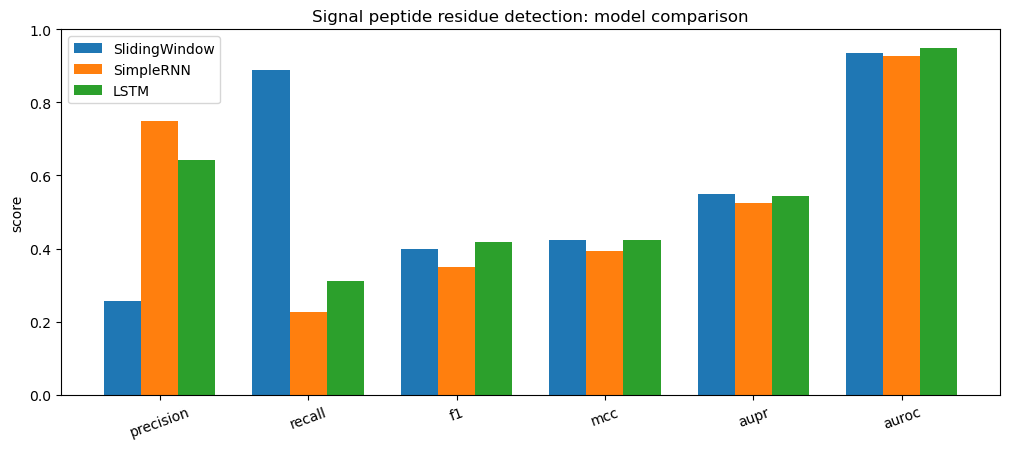

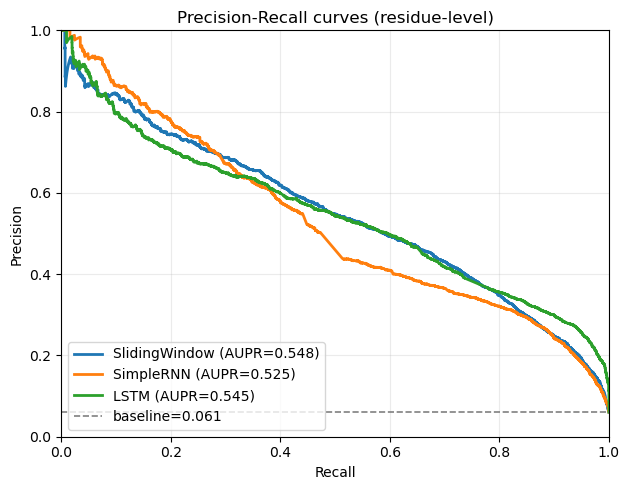

In [6]:
# Aggregate and visualize results
results = {
    "SlidingWindow": {**metrics_sw, "y": yte, "proba": proba_sw},
    "SimpleRNN": res_rnn,
    "LSTM": res_lstm,
}

metric_names = ["precision", "recall", "f1", "mcc", "aupr", "auroc"]
model_names = list(results.keys())

print("\nFinal test metrics")
for name in model_names:
    print(f"\n[{name}]")
    for m in metric_names:
        print(f"  {m:>9s}: {results[name][m]:.4f}")

plt.figure(figsize=(10.2, 4.6))
x = np.arange(len(metric_names))
w = 0.25
for i, name in enumerate(model_names):
    vals = [results[name][m] for m in metric_names]
    plt.bar(x + (i-1)*w, vals, width=w, label=name)

plt.xticks(x, metric_names, rotation=20)
plt.ylim(0, 1.0)
plt.ylabel("score")
plt.title("Signal peptide residue detection: model comparison")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.4, 5.0))
for name in model_names:
    y_true = results[name]["y"]
    p = results[name]["proba"]
    pr, rc, _ = precision_recall_curve(y_true, p)
    ap = average_precision_score(y_true, p)
    plt.plot(rc, pr, linewidth=2, label=f"{name} (AUPR={ap:.3f})")

baseline = np.mean(results[model_names[0]]["y"])
plt.axhline(baseline, linestyle="--", color="gray", linewidth=1.2, label=f"baseline={baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves (residue-level)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc="lower left")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5) Notes and extensions

- This notebook uses only sequence and UniProt signal-peptide annotation (`ft_signal`).
- The current objective is residue-wise binary tagging in the N-terminus.
- You can extend this to cleavage-site prediction (single boundary position) or multi-class region tagging (n-/h-/c-region).
- If the downloaded class balance is too skewed, increase `MAX_RECORDS` or perform per-protein balancing.